# B4_penapisan: Evaluasi Praktikum P1-P4 Computer Vision (SIMUTEH)
**Nama:** Rian | **NIM:** 2330511025 | **SEED:** 1025 | **Kelas:** 6A

## Bagian 4. Konvolusi dan Penapisan Spasial

In [1]:
import os, sys
# Jalankan dari folder notebook/ di dalam repository (jalur file selalu diawali ../).
if os.path.basename(os.getcwd()) != "notebook":
    cand = "/content/simuteh-2330511025/notebook"
    if os.path.exists(cand): os.chdir(cand)
    else: raise SystemExit("Buka notebook ini dari folder notebook/ di repository (di Colab: git clone repo-mu dahulu, lalu %cd simuteh-2330511025/notebook).")
sys.path.append("../src")
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd, time
from matplotlib.patches import FancyBboxPatch
from utils_cv import baca, tampil, kontras_bercak, statistik
if not os.path.exists("../data/sintetis/label.csv"):
    raise SystemExit("Dataset belum ada. Jalankan B1_lingkungan.ipynb dahulu (atau: cd .. lalu python src/buat_dataset_sintetis.py).")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
print("Folder kerja:", os.getcwd(), "| citra:", len(label))

Folder kerja: /tmp/repo/simuteh-2330511025/notebook | citra: 60


### Langkah 4.1 Lembar hitung manual

```
P = [[52, 55, 61, 58],     Q = [[70, 72, 75],      kernel tajam = [[ 0,-1, 0],
     [59,255, 64, 60],          [74,120, 78],                      [-1, 5,-1],
     [62, 60,  0, 57],          [73, 76, 79]]                      [ 0,-1, 0]]
     [58, 61, 59, 63]]
```
**a)** Keluaran 2 x 2 (posisi valid) memakai jendela 3 x 3 pada empat posisi. Setiap jendela memuat **kedua** piksel ekstrem (255 di (1,1) dan 0 di (2,2)).

- *Rerata 3 x 3:* jumlah jendela (0,0) = 52+55+61+59+255+64+62+60+0 = 668, jadi 668/9 = **74,22**. Hasil keempat posisi: 74,22; 74,44; 75,33; 75,44.
- *Gaussian 1/16:* posisi (0,0): (1·52+2·55+1·61) + (2·59+4·255+2·64) + (1·62+2·60+1·0) = 223 + 1266 + 182 = 1671, jadi 1671/16 = **104,44**. Hasil keempat posisi: 104,44; 77,38; 77,25; 57,44.
- *Median 3 x 3:* jendela (0,0) terurut: 0, 52, 55, 59, **60**, 61, 62, 64, 255, median = 60. Keempat posisi menghasilkan **60, 60, 60, 60**.

**b)** Piksel tengah Q (120) dengan kernel tajam: $5(120) - 72 - 74 - 78 - 76 = 600 - 300 = 300$, di-*clip* menjadi **255**.

**c)** Baris [12, 30, 45, 70], padding satu piksel:
- Zero padding: [0, 12, 30, 45, 70, 0]; rerata 1 x 3 piksel pertama = (0+12+30)/3 = **14,0**.
- Replicate: [12, 12, 30, 45, 70, 70]; rerata = (12+12+30)/3 = **18,0**.
- Reflect (BORDER_REFLECT_101): [30, 12, 30, 45, 70, 45]; rerata = (30+12+30)/3 = **24,0**.

In [2]:
P = np.array([[52,55,61,58],[59,255,64,60],[62,60,0,57],[58,61,59,63]], float)
G = np.array([[1,2,1],[2,4,2],[1,2,1]]) / 16
for nm, fn in [("rerata", lambda w: w.mean()), ("gaussian", lambda w: (w*G).sum()), ("median", lambda w: np.median(w))]:
    print(nm, [[round(float(fn(P[y:y+3, x:x+3])), 2) for x in range(2)] for y in range(2)])
Q = np.array([[70,72,75],[74,120,78],[73,76,79]]); ks = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
print("tajam Q:", (Q*ks).sum(), "-> clip", np.clip((Q*ks).sum(), 0, 255))
bar = np.array([12, 30, 45, 70])
for nm, mode in [("zero", "constant"), ("replicate", "edge"), ("reflect101", "reflect")]:
    pp = np.pad(bar, 1, mode=mode); print(f"{nm:10s}", pp, "rerata piksel pertama =", pp[:3].mean())

rerata [[74.22, 74.44], [75.33, 75.44]]
gaussian [[104.44, 77.38], [77.25, 57.44]]
median [[60.0, 60.0], [60.0, 60.0]]
tajam Q: 300 -> clip 255
zero       [ 0 12 30 45 70  0] rerata piksel pertama = 14.0
replicate  [12 12 30 45 70 70] rerata piksel pertama = 18.0
reflect101 [30 12 30 45 70 45] rerata piksel pertama = 24.0


### Langkah 4.2 Konvolusi manual vs `cv2.filter2D` (Kode 4.1)

In [3]:
def konvolusi(img, k):   # fungsi dari slide P4 (sebenarnya korelasi)
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)
def konvolusi_sejati(img, k):   # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))
nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md_ = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0); mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
for nm, k in {"rerata": np.ones((3, 3)) / 9, "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k); t_manual = time.perf_counter() - t0
    t0 = time.perf_counter(); b_ = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE); t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b_.astype(int)).max()
    c = konvolusi_sejati(bersih, k); beda2 = np.abs(c.astype(int) - b_.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.850 s, filter2D=0.00424 s


asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.603 s, filter2D=0.00040 s


### Langkah 4.3 Tiga penapis, dua jenis derau (Kode 4.2) dan Tabel 11

Tabel 11 (gauss_20 dan sp_4%)
          PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
tanpa       22.11  19.14     0.00   0.00     1.79  1.38
rerata_3    31.41  28.30     0.08   0.09     3.98  3.44
rerata_5    34.35  31.49     0.10   0.10     4.74  4.38
gauss_5     32.54  29.39     0.25   0.26     4.26  3.76
median_3    29.72  47.64     0.08   0.08     3.61  5.70
median_5    33.33  44.31     0.67   0.67     4.66  5.95
median_9    35.05  40.38    13.39  10.49     5.46  6.81


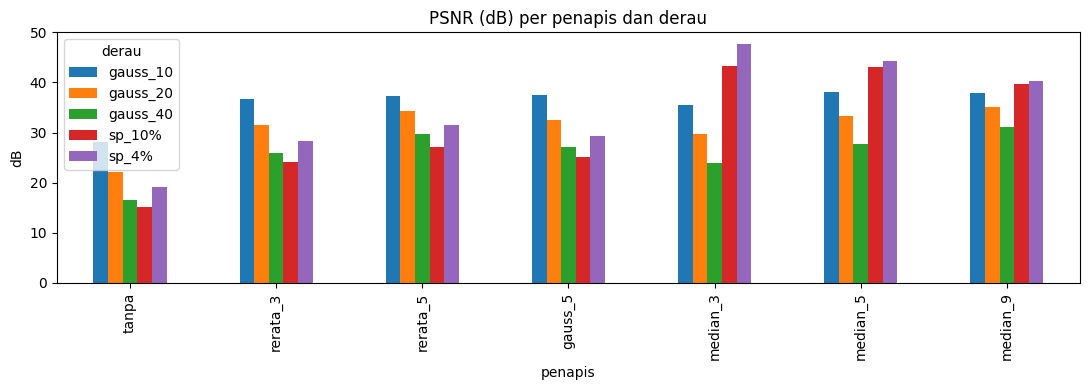

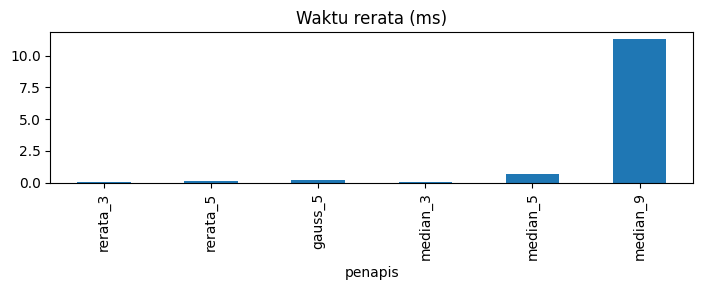

In [4]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd): return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape); out[m < p / 2] = 0; out[m > 1 - p / 2] = 255; return out
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)
derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20), "gauss_40": derau_gauss(bersih, 40),
         "sp_4%": derau_sp(bersih, 0.04), "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)), "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5), "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md_, mb)])
    for pn, f in penapis.items():
        out = f(d); baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md_, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)
t11 = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])].pivot(index="penapis", columns="derau", values=["PSNR_dB", "waktu_ms", "KB"])
order = ["tanpa", "rerata_3", "rerata_5", "gauss_5", "median_3", "median_5", "median_9"]
print("Tabel 11 (gauss_20 dan sp_4%)"); print(t11.loc[order])
pv = tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").loc[order]
pv.plot(kind="bar", figsize=(11, 4), title="PSNR (dB) per penapis dan derau"); plt.ylabel("dB"); plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr.png"); plt.show()
tw = tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau", values="waktu_ms").mean(axis=1).loc[order[1:]]
tw.plot(kind="bar", figsize=(7, 3), title="Waktu rerata (ms)"); plt.tight_layout(); plt.savefig("../hasil/b4_grafik_waktu.png"); plt.show()

### Langkah 4.4 Apakah bercak kecil terjaga? (Kode 4.3)

           dI    KB
kernel             
1       27.81  4.32
3       28.17  4.44
5       26.98  4.30
9       20.37  3.72
15       6.17  1.64


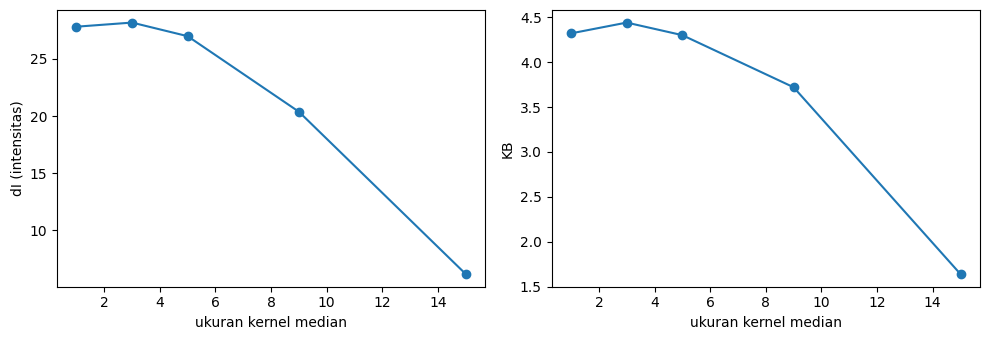

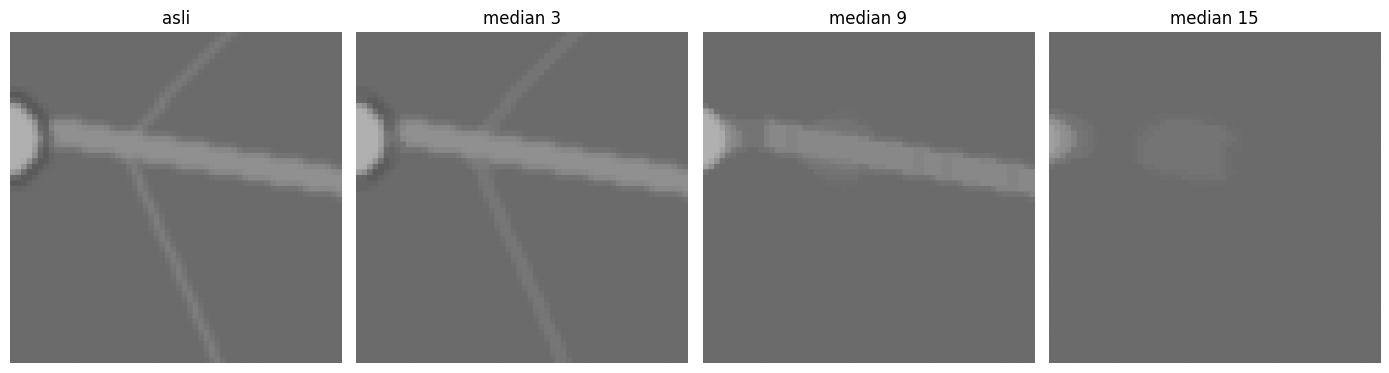

In [5]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float); sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g_ = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0); mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:
        out = g_ if k == 1 else cv2.medianBlur(g_, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2); print(rata)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(rata.index, rata.dI, "o-"); ax[0].set_xlabel("ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)")
ax[1].plot(rata.index, rata.KB, "o-"); ax[1].set_xlabel("ukuran kernel median"); ax[1].set_ylabel("KB")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_dI.png"); plt.show()
# potongan bercak diperbesar (crop) pada citra ringan teh_021
nm = "teh_021.png"; g_ = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY); mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
ys, xs = np.where(mb2 > 0); cy, cx = int(ys.mean()), int(xs.mean())
y0, x0 = max(cy - 30, 0), max(cx - 30, 0)
crops = [g_[y0:y0+60, x0:x0+60]] + [cv2.medianBlur(g_, k)[y0:y0+60, x0:x0+60] for k in (3, 9, 15)]
tampil([cv2.resize(c, None, fx=5, fy=5, interpolation=cv2.INTER_NEAREST) for c in crops], ["asli", "median 3", "median 9", "median 15"], ukuran=(14, 4))
plt.savefig("../hasil/b4_crop_bercak.png"); plt.show()

### Langkah 4.5 Urutan meredam derau dan menajamkan (Kode 4.4)

In [6]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0); return cv2.addWeighted(x, 1 + k, blur, -k, 0)
noisy = derau["gauss_20"]; latar = md_ == 0
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)); B = unsharp(redam(noisy))
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} sigma_latar={A[latar].std():.1f} | redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.38 sigma_latar=7.9 | redam->tajam PSNR=30.19 sigma_latar=8.3
Median: tajam->redam PSNR=30.11 sigma_latar=8.1 | redam->tajam PSNR=31.07 sigma_latar=7.3


### Langkah 4.6 PSNR 12 citra kondisi normal sebelum dan sesudah penapisan

In [7]:
res = []
for i in range(1, 61, 5):
    nm = f"teh_{i:03d}.png"
    c = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY); bs = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    res.append([nm, cv2.PSNR(bs, c), cv2.PSNR(bs, cv2.medianBlur(c, 3)), cv2.PSNR(bs, cv2.GaussianBlur(c, (5, 5), 1.0))])
r4 = pd.DataFrame(res, columns=["citra", "PSNR_tanpa", "PSNR_median3", "PSNR_gauss5"]).round(2)
print(r4.to_string(index=False)); print("\nRerata:"); print(r4.iloc[:, 1:].mean().round(2))
r4.to_csv("../hasil/b4_psnr_12_normal.csv", index=False)
print("\nP4.6: operasi kali kernel 5x5 -> 4000x3000:", 4000*3000*25/1e6, "juta | 640x480:", 640*480*25/1e6, "juta | rasio:", round(4000*3000/(640*480), 1))

      citra  PSNR_tanpa  PSNR_median3  PSNR_gauss5
teh_001.png       32.58         39.65        41.22
teh_006.png       29.98         37.34        39.41
teh_011.png       33.25         40.25        41.62
teh_016.png       29.69         37.04        39.08
teh_021.png       34.95         41.67        42.63
teh_026.png       31.70         38.82        40.34
teh_031.png       31.17         38.34        40.12
teh_036.png       34.87         41.49        41.94
teh_041.png       33.83         40.53        41.00
teh_046.png       31.64         38.77        40.54
teh_051.png       29.14         36.48        38.38
teh_056.png       35.73         42.19        41.78

Rerata:
PSNR_tanpa      32.38
PSNR_median3    39.38
PSNR_gauss5     40.67
dtype: float64

P4.6: operasi kali kernel 5x5 -> 4000x3000: 300.0 juta | 640x480: 7.68 juta | rasio: 39.1


### Jawaban Pertanyaan Analisis Bagian 4

**P4.1 Median vs rerata/Gaussian.** Pada setiap jendela 3 x 3, piksel garam (255) dan merica (0) hanya menempati ujung urutan data, sedangkan nilai ke-5 dari 9 data terurut tetap 60 (nilai daun). Karena itu median menghasilkan 60 di keempat posisi: nilai ekstrem **dibuang**. Rerata (74,22 sampai 75,44) dan Gaussian (57,44 sampai 104,44) ikut menghitung nilai ekstrem sehingga hasilnya berubah-ubah dan tercemar; pada Gaussian posisi (0,0), piksel 255 berada di pusat berbobot 4/16, hasilnya melonjak ke 104,44. Artinya, untuk derau garam dan merica median adalah penapis yang tepat karena ia kebal terhadap pencilan; rerata dan Gaussian hanya menyebarkan piksel rusak ke sekitarnya sehingga bintik terang yang kabur dapat menyerupai bercak.

**P4.2 Korelasi vs konvolusi.** Fungsi `konvolusi` pada slide **tidak membalik kernel**, jadi sebenarnya menghitung *korelasi silang*; `cv2.filter2D` juga mengerjakan korelasi (dokumentasi OpenCV menyebut ini). Itulah sebabnya hasil keduanya sama (selisih maksimum 0 untuk kedua kernel). Konvolusi sejati membalik kernel 180 derajat lebih dahulu; untuk kernel tak simetris (Sobel arah-x) hasilnya berbeda (selisih maksimum 255, karena membalik kernel Sobel mengubah tandanya sehingga respons positif menjadi negatif dan terpotong menjadi 0). Pada kernel rerata dan Gaussian, kernel simetris terhadap putaran 180 derajat, sehingga kernel yang dibalik identik dengan aslinya dan korelasi sama dengan konvolusi.

**P4.3 Penapis terbaik (Kode 4.2).**
- *Derau Gaussian 20:* PSNR tertinggi `median_9` (35,05 dB), lalu `rerata_5` (34,35), `median_5` (33,33), `gauss_5` (32,54), `rerata_3` (31,41), `median_3` (29,72); tanpa penapis 22,11 dB.
- *Garam-merica 4%:* PSNR tertinggi `median_3` (47,64 dB), jauh di atas rerata/Gaussian (28 sampai 31 dB).
- *Trade-off:* `median_9` unggul 0,7 dB atas `rerata_5` pada derau Gaussian, tetapi waktunya sekitar 100 kali lebih lama (sekitar 10 ms vs 0,09 ms) dan merusak bercak kecil (lihat P4.4). Untuk Gaussian, `rerata_5` atau `gauss_5` adalah pilihan seimbang (cepat, PSNR tinggi, KB 4,74 dan 4,26). Untuk garam-merica, `median_3` terbaik: PSNR tertinggi dan cepat (0,08 ms), KB 5,70 (median lebih besar memberi KB lebih tinggi, tetapi merusak bercak kecil). Keputusan berubah bila KB dan waktu ikut dipertimbangkan. *(Angka waktu berasal dari mesinku; cocokkan dengan milikmu.)*

**P4.4 Kernel median dan bercak ringan.** Rerata dI pada 20 citra ringan: kernel 1 = 27,81; 3 = 28,17; 5 = 26,98; 9 = 20,37; 15 = 6,17. Bercak mulai hilang pada kernel **9** (dI turun sekitar 27% dari tanpa penapis) dan nyaris lenyap pada kernel **15** (turun 78%). Alasan: median menghapus struktur yang lebih kecil dari sekitar setengah luas jendela, dan bercak ringan hanya berdiameter 10 sampai 18 piksel. KB tetap tinggi pada kernel sedang (3,72 pada kernel 9 vs 4,32 tanpa penapis) karena KB dibagi simpangan baku daun sehat: median juga meratakan tekstur dan derau daun sehat sehingga penyebut mengecil dan menutupi turunnya selisih. **Pelajaran:** satu ukuran dapat menyesatkan; laporkan dI dan KB bersamaan (pembilang dan penyebut) dan periksa visual, agar penapis yang membuang bercak tidak lolos hanya karena KB-nya baik.

**P4.5 Urutan redam dan tajam.** Tidak selalu lebih baik. Untuk Gaussian, tajam dahulu lalu redam memberi PSNR 30,38 dan σ latar 7,9; redam dahulu lalu tajam memberi 30,19 dan 8,3, hampir sama (bahkan urutan pertama sedikit lebih tinggi). Untuk median: tajam lalu redam 30,11 dan σ latar 8,1; redam lalu tajam 31,07 dan 7,3, jadi urutan redam dahulu lebih baik. Alasan: Gaussian dan unsharp masking keduanya linear dan tak berubah terhadap geseran (konvolusi), sehingga bersifat komutatif; urutan tidak mengubah hasil (selisih kecil hanya akibat pembulatan dan *clipping* 8 bit). Median tidak linear, jadi urutan penting: bila menajamkan dahulu, derau ikut diperkuat sebelum median dan tidak seluruhnya terbuang.

**P4.6 Jumlah operasi.** Kernel 5 x 5 butuh 25 perkalian per piksel: foto 4000 x 3000 = 12 juta piksel x 25 = **300 juta** perkalian; citra 640 x 480 = 307.200 piksel x 25 = **7,68 juta** (39 kali lebih sedikit). Pada Kode 4.1, kernel 3 x 3 (9 perkalian) di citra 640 x 480 memakan sekitar 1,3 detik dengan perulangan Python; kernel 5 x 5 kira-kira 3,6 detik, dan untuk foto asli sekitar 39 kali lebih lama (dua menit lebih). Itu tidak sesuai kebutuhan pengguna nomor 4 (cepat di ponsel kelas menengah). Jadi foto harus diperkecil ke 640 piksel dan memakai fungsi pustaka (`filter2D`, `blur`, `medianBlur`) yang dioptimalkan, yang selesai dalam sekitar 0,4 sampai 4 ms.

**P4.7 Wajah tidak sengaja terfoto.** Blur ringan tidak cukup karena struktur wajah, bentuk kepala, rambut, pakaian, dan konteks masih dapat dikenali, dan blur ringan dapat dipulihkan sebagian (dekonvolusi) atau dikenali oleh model pengenalan wajah. Prosedur lebih aman: (1) hentikan penyimpanan dan jangan unggah foto itu; (2) deteksi wajah lalu tutup dengan kotak solid (bukan blur) atau potong bagian itu; (3) hapus berkas asli dan EXIF, simpan hanya versi yang sudah aman; (4) bila memungkinkan ambil ulang foto tanpa orang; (5) minta persetujuan petani dan batasi akses.